In [1]:
!ls ../models

args.yaml  best_int8.tflite  best_ncnn_model  best_ncnn_model_640  best.pt


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ai_edge_litert.interpreter import Interpreter
from glob import glob

model_path = "../models/best_int8.tflite" 
interpreter = Interpreter(model_path=model_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_shape = input_details[0]['shape']
is_nchw = True if (input_shape[1] == 3 or input_shape[1] == 1) else False
h_in, w_in = (input_shape[2], input_shape[3]) if is_nchw else (input_shape[1], input_shape[2])

CLASS_NAMES = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'K', 'L', 'M',
               'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'Y', 'W' ]

IMGSZ = 640
imagens_teste = glob("../dataset/*.jpg") + glob("../dataset/*.jpeg")

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.




ANALISANDO A IMAGEM: ../dataset/A.jpg
Detectou 'A' com alta confiança (50.2%).


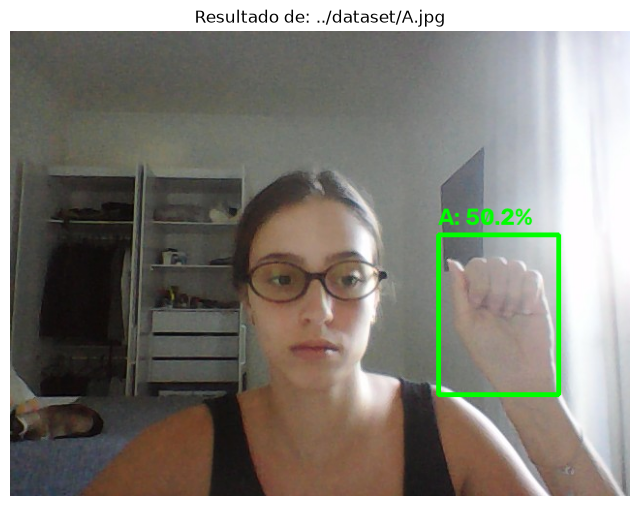



ANALISANDO A IMAGEM: ../dataset/E.jpg
Detectou 'E' com baixa confiança (36.7%).


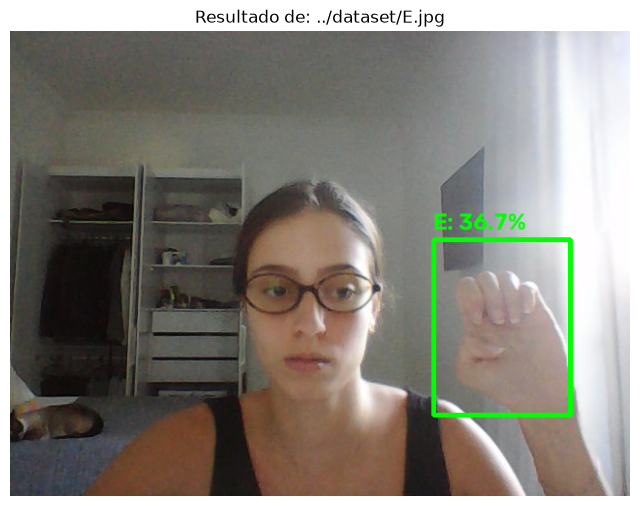



ANALISANDO A IMAGEM: ../dataset/C.jpg
Detectou 'C' com alta confiança (50.2%).


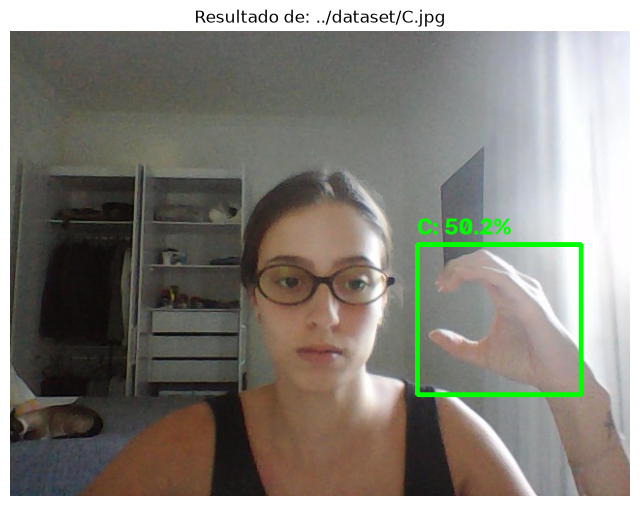



ANALISANDO A IMAGEM: ../dataset/B.jpg
Detectou 'B' com alta confiança (50.2%).


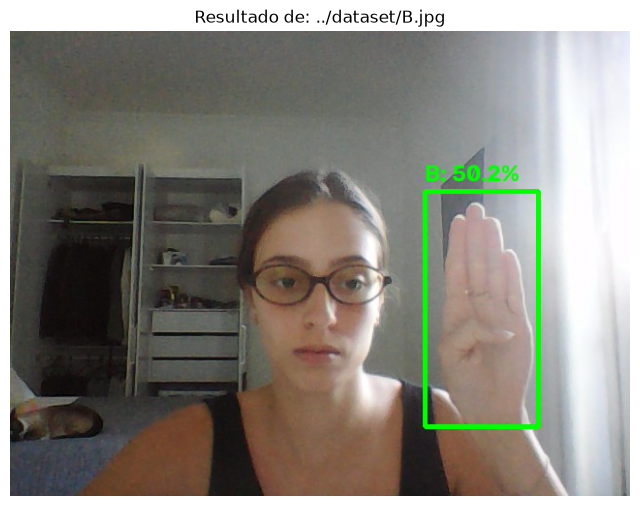



ANALISANDO A IMAGEM: ../dataset/F.jpg
Detectou 'F' com alta confiança (50.2%).


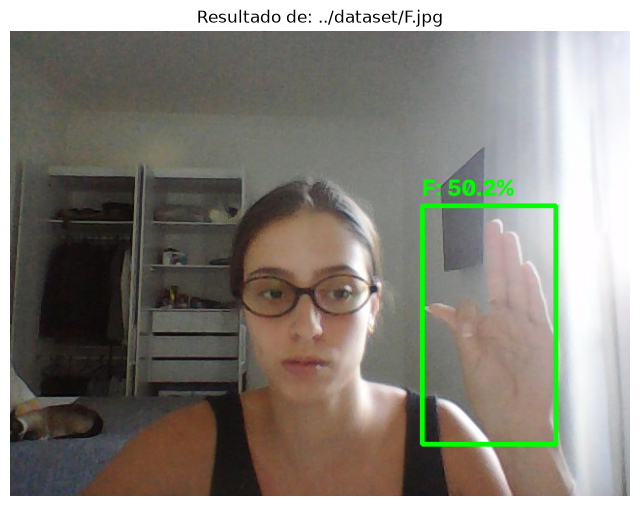



ANALISANDO A IMAGEM: ../dataset/D.jpg
Detectou 'C' com baixa confiança (38.9%).


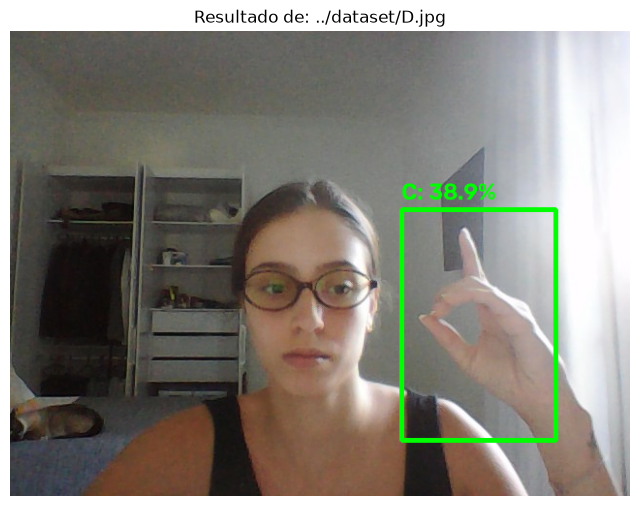



ANALISANDO A IMAGEM: ../dataset/W.jpeg
Detectou 'T' com alta confiança (50.2%).


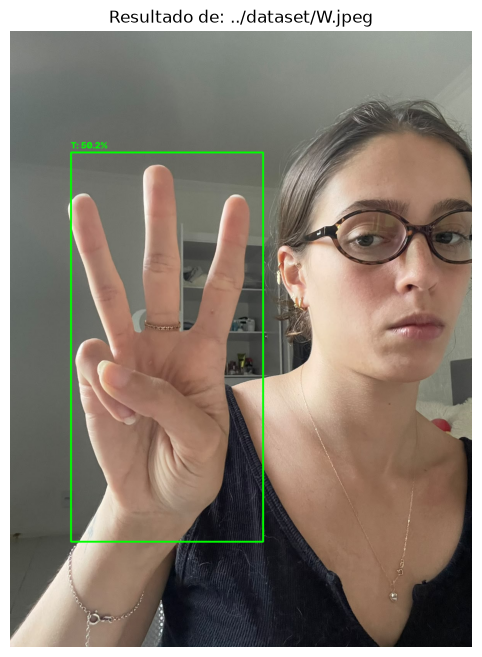



ANALISANDO A IMAGEM: ../dataset/U.jpeg
Detectou 'U' com alta confiança (50.2%).


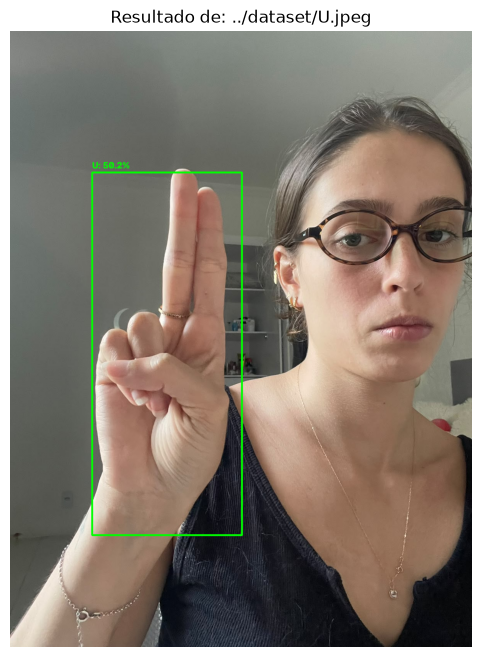



ANALISANDO A IMAGEM: ../dataset/M.jpeg
Detectou 'M' com alta confiança (50.2%).


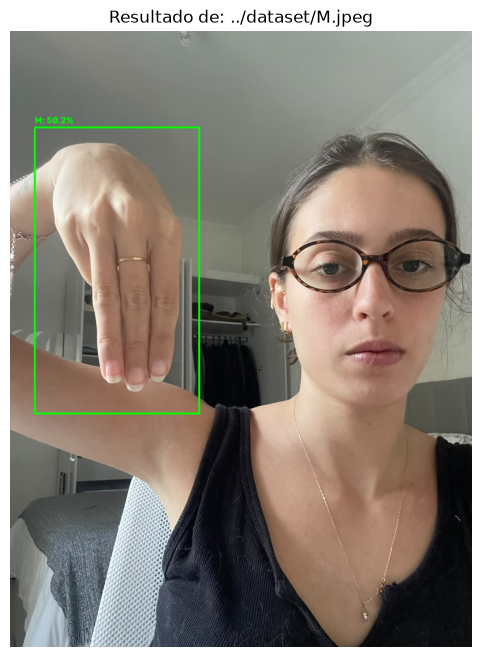



ANALISANDO A IMAGEM: ../dataset/L.jpeg
Detectou 'L' com alta confiança (50.2%).


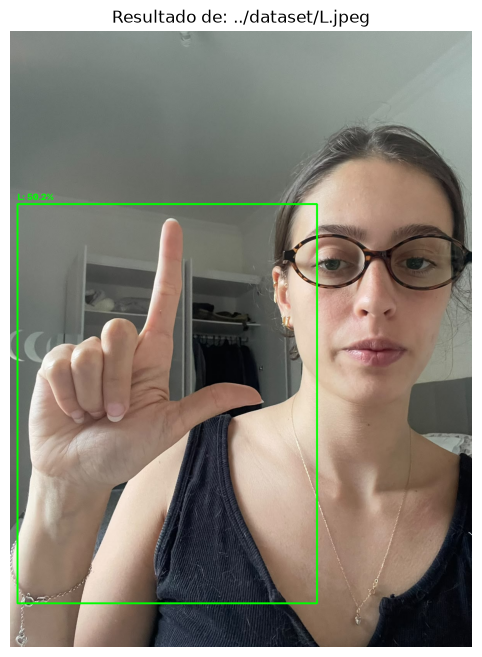



ANALISANDO A IMAGEM: ../dataset/N.jpeg
O modelo não encontrou nada na imagem.


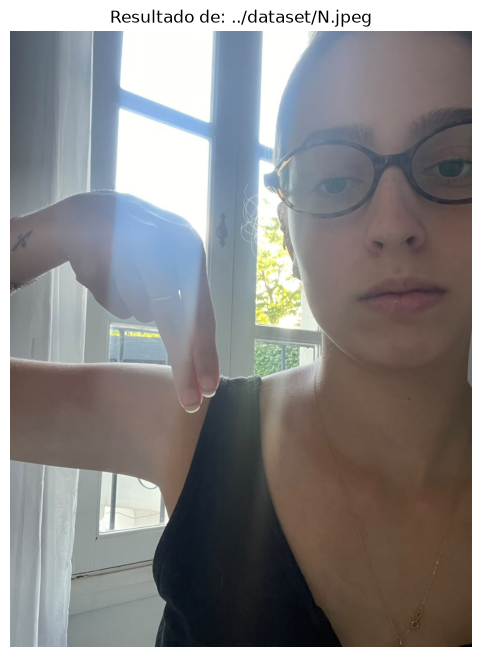



ANALISANDO A IMAGEM: ../dataset/P.jpeg
O modelo não encontrou nada na imagem.


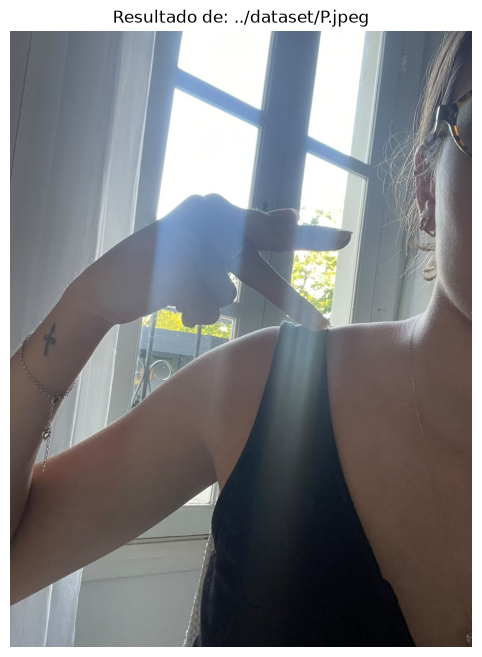



ANALISANDO A IMAGEM: ../dataset/R.jpeg
Detectou 'R' com alta confiança (50.2%).


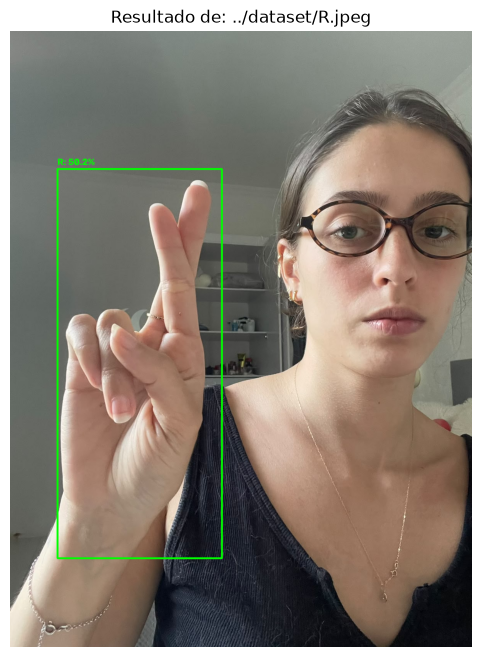



ANALISANDO A IMAGEM: ../dataset/S.jpeg
Detectou 'S' com alta confiança (50.2%).


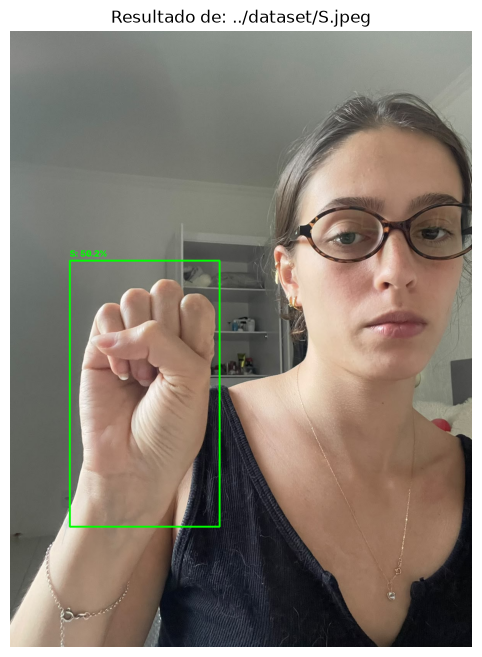



ANALISANDO A IMAGEM: ../dataset/I.jpeg
Detectou 'I' com alta confiança (50.2%).


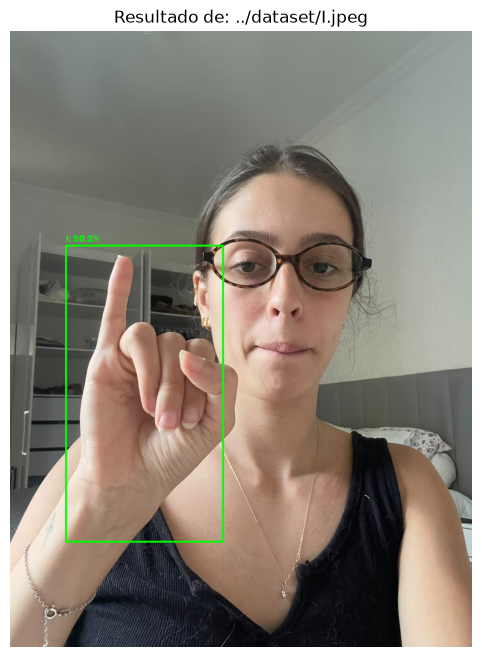



ANALISANDO A IMAGEM: ../dataset/O.jpeg
O modelo não encontrou nada na imagem.


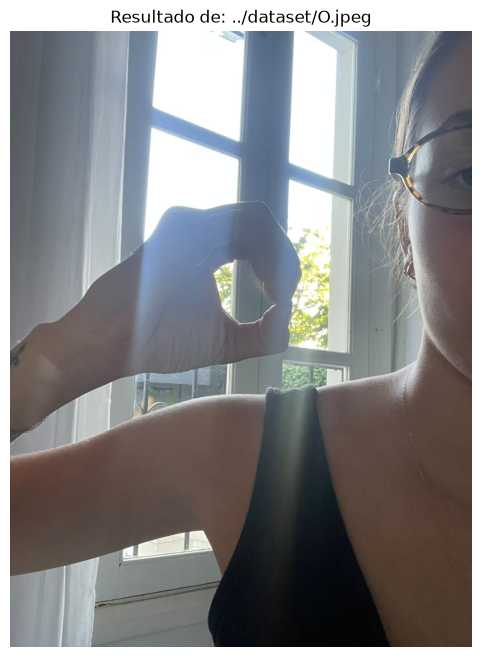



ANALISANDO A IMAGEM: ../dataset/T.jpeg
Detectou 'F' com alta confiança (50.2%).


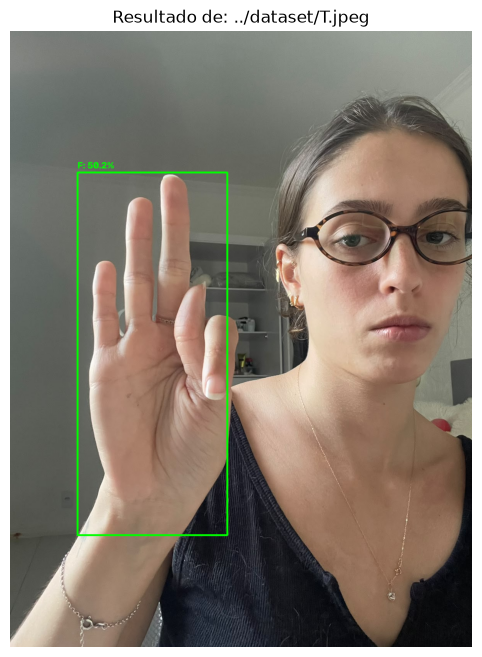



ANALISANDO A IMAGEM: ../dataset/Q.jpeg
O modelo não encontrou nada na imagem.


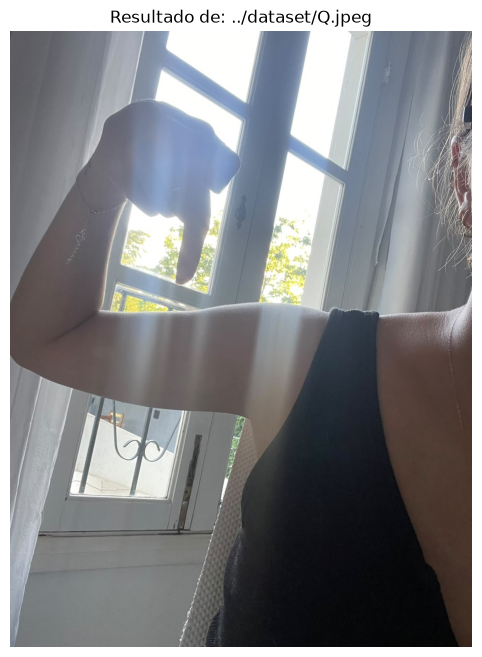

In [3]:
for caminho_img in imagens_teste:
    img_bgr = cv2.imread(caminho_img)
    if img_bgr is None:
        continue
    
    h_orig, w_orig = img_bgr.shape[:2]
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (w_in, h_in))

    if input_details[0]['dtype'] == np.float32:
        norm_img = img_resized.astype(np.float32) / 255.0
    else:
        scale, zero_point = input_details[0]['quantization']
        if scale > 0:
            norm_img = (img_resized.astype(np.float32) / 255.0 / scale + zero_point).astype(input_details[0]['dtype'])
        else:
            norm_img = img_resized.astype(input_details[0]['dtype'])

    if is_nchw:
        norm_img = np.transpose(norm_img, (2, 0, 1))

    input_data = np.expand_dims(norm_img, axis=0)

    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()

    output_data = interpreter.get_tensor(output_details[0]['index'])
    if output_details[0]['dtype'] in (np.int8, np.uint8):
        scale, zero_point = output_details[0]['quantization']
        if scale > 0:
            output_data = (output_data.astype(np.float32) - zero_point) * scale

    output = output_data[0]
    if output.shape[0] < output.shape[1]:
        output = output.T

    boxes_cxcywh = output[:, :4]
    scores_matrix = output[:, 4:]

    class_ids = np.argmax(scores_matrix, axis=1)
    confidences = np.max(scores_matrix, axis=1)
    mask = confidences >= 0.20
    
    filtered_boxes = boxes_cxcywh[mask]
    filtered_scores = confidences[mask]
    filtered_class_ids = class_ids[mask]

    boxes_for_nms = []
    if len(filtered_boxes) > 0:
        is_normalized = np.max(filtered_boxes) <= 1.5
        scale_x = w_orig if is_normalized else (w_orig / w_in)
        scale_y = h_orig if is_normalized else (h_orig / h_in)

        for box in filtered_boxes:
            cx, cy, w_box, h_box = box
            x1 = int((cx - w_box / 2.0) * scale_x)
            y1 = int((cy - h_box / 2.0) * scale_y)
            wb = int(w_box * scale_x)
            hb = int(h_box * scale_y)
            boxes_for_nms.append([x1, y1, wb, hb])

    indices = cv2.dnn.NMSBoxes(
        bboxes=boxes_for_nms,
        scores=filtered_scores.tolist(),
        score_threshold=0.20,
        nms_threshold=0.40
    )

    print(f"\n\nANALISANDO A IMAGEM: {caminho_img}")

    if len(indices) == 0:
        print("O modelo não encontrou nada na imagem.")
    else:
        indices = indices.flatten() if hasattr(indices, 'flatten') else indices
        for idx in indices:
            cls_id = int(filtered_class_ids[idx])
            conf_val = float(filtered_scores[idx])
            nome_classe = CLASS_NAMES[cls_id] if cls_id < len(CLASS_NAMES) else f"Classe_{cls_id}"

            if conf_val > 0.5:
                print(f"Detectou '{nome_classe}' com alta confiança ({conf_val:.1%}).")
            else:
                print(f"Detectou '{nome_classe}' com baixa confiança ({conf_val:.1%}).")

            # Desenhar caixa e rótulo na imagem
            x1, y1, wb, hb = boxes_for_nms[idx]
            cv2.rectangle(img_rgb, (x1, y1), (x1 + wb, y1 + hb), (0, 255, 0), 3)
            label = f"{nome_classe}: {conf_val:.1%}"
            cv2.putText(img_rgb, label, (x1, max(25, y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

    # Exibição do Resultado
    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title(f"Resultado de: {caminho_img}")
    plt.show()